# News NER Project


In [ ]:
import json
import time
from pathlib import Path
import requests
import pandas as pd
API_KEY = 'MASUKKAN API KAMU DI SINI'  # Ganti dengan API Key kamu
BASE_URL = "https://indonewsapi.web.id"
REQUEST_ID = "f98db991-8ce8-4aa3-9cec-145632f51f26"  # Simpan ID ini untuk retry
headers = {"Authorization": "Bearer " + API_KEY, "Idempotency-Key": REQUEST_ID}
params = {
    "limit": "5000",
    "page": "1",
    "from": "2026-08-29",
    "to": "2026-10-29",
    "search_in": "title_summary",
    "q": "karhutla"
}

def get_json(url, **options):
    response = requests.get(url, headers=headers, **options)
    response.raise_for_status()
    return response.json()

result = get_json("https://indonewsapi.web.id/v1/fulltext/search", params=params)

while "export" in result:
    job = result["export"]
    if job["state"] == "complete":
        result = get_json(BASE_URL + job["resultUrl"])
        break
    if job["state"] not in ("queued", "running"):
        raise RuntimeError(job.get("error") or job["state"])
    print(f"Menunggu: {job['collected']}/{job['requested']} artikel", flush=True)
    time.sleep(5)
    result = get_json(BASE_URL + job["statusUrl"])

if not isinstance(result.get("data"), list):
    raise RuntimeError("Respons tidak berisi data artikel")
ROOT = Path.cwd()
if not (ROOT / 'datasets').exists():
    ROOT = ROOT.parent

news = pd.json_normalize(result['data'], sep='_')
OUTPUT_API = ROOT / 'datasets' / 'indonesia_fire_news_api.csv'
news.to_csv(OUTPUT_API, index=False, encoding='utf-8-sig')
print(f"Selesai: {len(news):,} artikel disimpan di {OUTPUT_API}")

Menunggu: 0/5000 artikel
Menunggu: 400/5000 artikel
Menunggu: 900/5000 artikel
Menunggu: 1400/5000 artikel
Menunggu: 1900/5000 artikel
Menunggu: 2300/5000 artikel
Menunggu: 2800/5000 artikel
Menunggu: 3100/5000 artikel
Menunggu: 3500/5000 artikel
Menunggu: 4000/5000 artikel
Selesai: 4321 artikel disimpan di hasil.json


In [28]:
# 1. DEDUPLICATION: ID API dulu, lalu URL artikel.
before = len(news)
news = news.drop_duplicates(subset='id')
news = news.drop_duplicates(subset='canonical_url')
news = news.reset_index(drop=True)

print(f'Sebelum: {before:,}')
print(f'Sesudah: {len(news):,}')
print(f'Dihapus: {before - len(news):,}')

OUTPUT_FILE = ROOT / 'datasets' / 'indonesia_fire_news_2y_deduplicated.csv'
news.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print('File bersih tersimpan:', OUTPUT_FILE)

Sebelum: 4,908
Sesudah: 4,908
Dihapus: 0
File bersih tersimpan: /home/dell7550/Downloads/free news/datasets/indonesia_fire_news_2y_deduplicated.csv


In [29]:
# 2. EDA: rentang waktu, sumber, dan panjang isi berita.
news['published_at'] = pd.to_datetime(news['published_at'], utc=True)
news['content_length'] = news['content'].fillna('').str.len()

print('Rentang tanggal:', news['published_at'].min(), 'sampai', news['published_at'].max())
print('\nTop 10 sumber:')
display(news['source_name'].value_counts().head(10))
print('\nPanjang isi artikel:')
display(news['content_length'].describe())

Rentang tanggal: 2026-08-29 01:31:20+00:00 sampai 2026-10-29 01:55:28+00:00

Top 10 sumber:


source_name
media indonesia    735
Detik              322
Jawa Pos           298
Suara.com          261
Republika          184
CNBC Indonesia     161
Antara Kalteng     150
Antara Sumsel      141
Sindo News         134
Antara Jambi       111
Name: count, dtype: int64


Panjang isi artikel:


count     4908.000000
mean      2771.350041
std       1309.413869
min         45.000000
25%       2003.750000
50%       2576.000000
75%       3304.250000
max      21834.000000
Name: content_length, dtype: float64

In [32]:
# EDA: kualitas data untuk kebutuhan NER

def unique_count(series):
    return series.map(
        lambda value: json.dumps(
            value,
            ensure_ascii=False,
            sort_keys=True
        ) if isinstance(value, (list, dict)) else value
    ).nunique()

quality = pd.DataFrame({
    'missing': news.isna().sum(),
    'unique': {
        column: unique_count(news[column])
        for column in news.columns
    },
    'dtype': news.dtypes.astype(str)
}).sort_values('missing', ascending=False)

display(quality)

print('Judul kosong:', news['title'].fillna('').str.strip().eq('').sum())
print('Isi berita kosong:', news['content'].fillna('').str.strip().eq('').sum())

print('Top 10 kategori:')
display(
    news['category']
    .fillna('Tidak diketahui')
    .astype(str)
    .value_counts()
    .head(10)
)

news['word_count'] = (
    news['content']
    .fillna('')
    .astype(str)
    .str.split()
    .str.len()
)

print('Statistik jumlah kata isi berita:')
display(news['word_count'].describe())

print('Contoh berita terpendek:')
display(
    news[['title', 'content', 'word_count']]
    .sort_values('word_count')
    .head(3)
)

,missing,unique,dtype
category,1081,230,str
author,293,787,str
summary,4,4735,str
tags,0,3038,object
rank,0,2,int64
id,0,4908,str
images,0,4564,object
title,0,4726,str
content,0,4790,str
media_id,0,152,str


Judul kosong: 0
Isi berita kosong: 0
Top 10 kategori:


category
News                 1381
Tidak diketahui      1081
Nusantara             445
Humaniora             277
Nasional              149
Daerah                 89
Indonesia              73
Politik Dan Hukum      54
Regional               52
Hukum                  42
Name: count, dtype: int64

Statistik jumlah kata isi berita:


count    4908.000000
mean      364.590261
std       170.238453
min         6.000000
25%       264.000000
50%       338.000000
75%       434.250000
max      2877.000000
Name: word_count, dtype: float64

Contoh berita terpendek:


,title,content,word_count
568,Infografik: 32 Korporasi Disanksi Terkait Karh...,Infografik: 32 Korporasi disanksi terkait karh...,6
2208,Minta Maaf Soal Pernyataan Kehidupan Normal sa...,Kepala BNPB Letjen TNI Suharyanto. (istimewa),6
4803,Infografik: Melindungi Satwa di Lokasi Karhutla,Infografik: Melindungi Satwa di Lokasi Karhutla,6


In [33]:
# 5. PREPROCESSING RINGAN UNTUK NER
# Jangan hapus stopword, jangan stemming, dan jangan lowercase.
# NER membutuhkan konteks kalimat dan posisi karakter entitas.

news['title'] = news['title'].fillna('').astype(str)
news['content'] = news['content'].fillna('').astype(str)

# Normalisasi whitespace saja; teks asli tetap dipertahankan.
news['text'] = (
    news['title'] + '. ' + news['content']
).str.replace(r'\s+', ' ', regex=True).str.strip()

news = news[news['text'].str.len() > 0].reset_index(drop=True)
print(f'Dokumen siap untuk anotasi: {len(news):,}')
display(news[['title', 'text']].head(2))

Dokumen siap untuk anotasi: 4,908


,title,text
0,Pemkab Tabalong inventarisasi kebutuhan penang...,Pemkab Tabalong inventarisasi kebutuhan penang...
1,"30 Tahun Karhutla Riau Tak Bermuara, WALHI Des...","30 Tahun Karhutla Riau Tak Bermuara, WALHI Des..."


In [34]:
# 6. SPLIT DATA DAN TEMPLATE ANOTASI NER
# Split dilakukan sebelum anotasi agar evaluasi tidak bocor.
shuffled = news.sample(frac=1, random_state=42).reset_index(drop=True)
n_train = int(len(shuffled) * 0.80)
n_valid = int(len(shuffled) * 0.10)

train = shuffled.iloc[:n_train].copy()
valid = shuffled.iloc[n_train:n_train + n_valid].copy()
test = shuffled.iloc[n_train + n_valid:].copy()

for name, frame in [('train', train), ('valid', valid), ('test', test)]:
    frame.to_csv(ROOT / 'datasets' / f'ner_{name}.csv', index=False, encoding='utf-8-sig')

# Sampel awal untuk anotasi manual.
annotation_sample = train.sample(n=min(300, len(train)), random_state=42)
annotation_file = ROOT / 'datasets' / 'ner_annotation_template.jsonl'
with open(annotation_file, 'w', encoding='utf-8') as file:
    for _, row in annotation_sample.iterrows():
        item = {
            'id': str(row['id']),
            'text': row['text'],
            'entities': []
        }
        file.write(json.dumps(item, ensure_ascii=False) + '\n')

print(f'Train: {len(train):,} | Valid: {len(valid):,} | Test: {len(test):,}')
print(f'Template anotasi: {annotation_file}')
print('Label awal: PERSON, ORG, LOC, DATE, EVENT')

Train: 3,926 | Valid: 490 | Test: 492
Template anotasi: /home/dell7550/Downloads/free news/datasets/ner_annotation_template.jsonl
Label awal: PERSON, ORG, LOC, DATE, EVENT


In [35]:
# 7. AUTO-LABEL NER: silver labels dari model Bahasa Indonesia.
# Hasil ini siap dipakai untuk eksplorasi dan review, tetapi bukan pengganti gold label manual.
import torch
from transformers import pipeline

MODEL_NAME = 'cahya/bert-base-indonesian-NER'
DEVICE = 0 if torch.cuda.is_available() else -1
ner_model = pipeline(
    'token-classification',
    model=MODEL_NAME,
    aggregation_strategy='simple',
    device=DEVICE,
)

LABEL_MAP = {
    'PER': 'PERSON', 'ORG': 'ORG', 'LOC': 'LOC', 'GPE': 'LOC',
    'DAT': 'DATE', 'TIM': 'TIME', 'EVT': 'EVENT',
}

# Gunakan teks ringkas agar setiap contoh muat dalam konteks model.
summary = news['summary'].fillna('').astype(str)
excerpt = news['content_excerpt'].fillna('').astype(str)
silver = news[['id', 'title']].copy()
silver['text'] = (news['title'].fillna('').astype(str) + '. ' + summary.where(summary.str.strip().ne(''), excerpt))
silver['text'] = silver['text'].str.replace(r'\s+', ' ', regex=True).str.strip().str.slice(0, 450)

def normalize_predictions(text, predictions, min_score=0.75):
    return [
        {
            'start': item['start'],
            'end': item['end'],
            'label': LABEL_MAP.get(item['entity_group'], item['entity_group']),
            'text': text[item['start']:item['end']],
            'score': round(float(item['score']), 4),
        }
        for item in predictions
        if item['score'] >= min_score
    ]

predictions = ner_model(silver['text'].tolist(), batch_size=32)
silver['entities'] = [normalize_predictions(text, items) for text, items in zip(silver['text'], predictions)]
silver['entity_count'] = silver['entities'].str.len()
silver['entities_json'] = silver['entities'].apply(json.dumps, ensure_ascii=False)

silver_file = ROOT / 'datasets' / 'ner_silver_labeled.csv'
silver[['id', 'title', 'text', 'entities_json', 'entity_count']].to_csv(
    silver_file, index=False, encoding='utf-8-sig'
)
print(f'Selesai: {len(silver):,} dokumen diberi silver label di {silver_file}')
display(silver[['title', 'entities', 'entity_count']].head())

/home/dell7550/.pyenv/versions/3.11.13/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Some weights of the model checkpoint at cahya/bert-base-indonesian-NER were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cpu
Asking to truncate to max_length

KeyboardInterrupt: 

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

FILE = "datasets/ner_silver_labeled_fulltext.csv"

df = pd.read_csv(FILE, dtype={"id": str})
df["entities"] = df["entities_json"].apply(json.loads)

print("Jumlah artikel:", len(df))
df[["id", "title", "entity_count"]].head()

Jumlah artikel: 4908


,id,title,entity_count
0,6182058,Pemkab Tabalong inventarisasi kebutuhan penang...,31
1,6095933,"30 Tahun Karhutla Riau Tak Bermuara, WALHI Des...",39
2,6077977,"Karhutla Kembali Muncul di Kalteng, Petugas Be...",20
3,6067759,"Karhutla Indonesia, WCC Tegaskan Solidaritas b...",34
4,5921390,Tim gabungan PPU padamkan karhutla di Buluminu...,38


In [4]:
entities_df = (
    df[["id", "title", "text", "entity_count", "entities"]]
    .explode("entities")
    .dropna(subset=["entities"])
    .reset_index(drop=True)
)

# Ganti nama text milik entitas agar tidak bentrok dengan text artikel.
entities_normalized = (
    pd.json_normalize(entities_df["entities"])
    .rename(columns={"text": "entity_text"})
)

entities_df = pd.concat(
    [
        entities_df.drop(columns="entities"),
        entities_normalized,
    ],
    axis=1,
)

print("Jumlah entitas:", len(entities_df))

entities_df[
    ["id", "label", "entity_text", "score", "start", "end", "text"]
].head(10)

Jumlah entitas: 178816


,id,label,entity_text,score,start,end,text
0,6182058,NOR,Pemkab Tabalong,0.9694,0,15,Pemkab Tabalong inventarisasi kebutuhan penang...
1,6182058,NOR,Pemerintah Kabupaten Tabalong,0.9236,80,109,Pemkab Tabalong inventarisasi kebutuhan penang...
2,6182058,LOC,Kalimantan Selatan,0.8101,111,129,Pemkab Tabalong inventarisasi kebutuhan penang...
3,6182058,MON,Rp10 miliar,0.9951,287,298,Pemkab Tabalong inventarisasi kebutuhan penang...
4,6182058,NOR,Bupati Tabalong,0.9837,300,315,Pemkab Tabalong inventarisasi kebutuhan penang...
5,6182058,PERSON,H Muhammad Noor Rifani,0.9488,317,339,Pemkab Tabalong inventarisasi kebutuhan penang...
6,6182058,PERSON,Noor Rifani,0.9878,593,604,Pemkab Tabalong inventarisasi kebutuhan penang...
7,6182058,DATE,Kamis (29/10/2026),0.9929,606,624,Pemkab Tabalong inventarisasi kebutuhan penang...
8,6182058,PRD,Alkon,0.8740,717,722,Pemkab Tabalong inventarisasi kebutuhan penang...
9,6182058,PRD,mesin pemadam jinjing dan gendong,0.9321,725,758,Pemkab Tabalong inventarisasi kebutuhan penang...


In [6]:
df["entity_count_actual"] = df["entities"].apply(len)
df["jumlah_sama"] = df["entity_count"] == df["entity_count_actual"]

entities_df["offset_valid"] = entities_df.apply(
    lambda row: row["entity_text"] == row["text"][int(row["start"]):int(row["end"])],
    axis=1,
)

print("entity_count sesuai:", df["jumlah_sama"].mean() * 100, "%")
print("offset entitas valid:", entities_df["offset_valid"].mean() * 100, "%")

entity_count sesuai: 100.0 %
offset entitas valid: 100.0 %


In [7]:
entities_df["score"] = pd.to_numeric(entities_df["score"], errors="coerce")

label_summary = (
    entities_df.groupby("label")
    .agg(
        jumlah_entitas=("label", "size"),
        jumlah_artikel=("id", "nunique"),
        rata_rata_score=("score", "mean"),
        score_minimum=("score", "min"),
        score_maksimum=("score", "max"),
    )
    .sort_values("jumlah_entitas", ascending=False)
)

display(label_summary.round(3))

,jumlah_entitas,jumlah_artikel,rata_rata_score,score_minimum,score_maksimum
label,,,,,
LOC,47289,4787,0.945,0.750,0.999
NOR,36739,4365,0.917,0.750,0.996
PERSON,29466,4688,0.945,0.750,0.999
CRD,15180,3119,0.891,0.750,0.995
DATE,12731,4523,0.963,0.750,0.999
ORG,12106,3568,0.878,0.750,0.995
QTY,9186,2498,0.947,0.750,0.996
PRD,6562,2040,0.875,0.750,0.995
EVENT,2213,1267,0.858,0.750,0.995


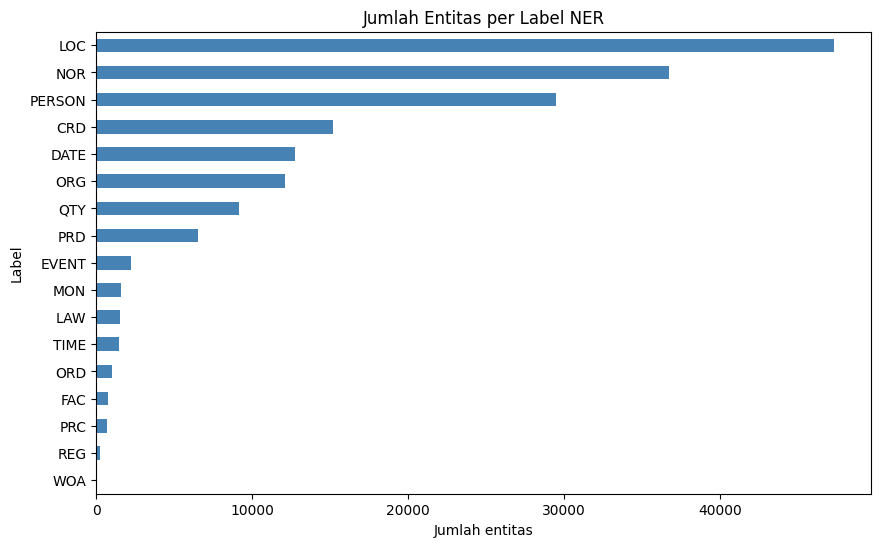

In [8]:
import matplotlib.pyplot as plt

label_summary["jumlah_entitas"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="steelblue",
    title="Jumlah Entitas per Label NER",
)

plt.xlabel("Jumlah entitas")
plt.ylabel("Label")
plt.show()

In [9]:
low_confidence = (
    entities_df[
        ["id", "title", "label", "entity_text", "score", "text"]
    ]
    .copy()
    .sort_values("score", ascending=True)
)

low_confidence["article_preview"] = low_confidence["text"].str[:250] + "..."
low_confidence[
    ["id", "title", "label", "entity_text", "score", "article_preview"]
].head(30)

,id,title,label,entity_text,score,article_preview
73258,4073285,Papua Barat perpanjang status tanggap darurat ...,PRD,asap karhutal,0.7500,Papua Barat perpanjang status tanggap darurat ...
91345,299751,Pemerintah Pastikan Karhutla Tidak akan Tembus...,LOC,Karhutla Bromo,0.7500,Pemerintah Pastikan Karhutla Tidak akan Tembus...
130787,4118214,Jambi Masuk Daftar 5 Provinsi Prioritas Penang...,PERSON,il,0.7500,Jambi Masuk Daftar 5 Provinsi Prioritas Penang...
17581,2424267,Satgas karhutla padamkan dua hektare lahan ter...,LOC,Palembang,0.7500,Satgas karhutla padamkan dua hektare lahan ter...
29779,3858755,Zaskia Adya Mecca Ungkap Kondisi Wajahnya saat...,PRD,masker,0.7500,Zaskia Adya Mecca Ungkap Kondisi Wajahnya saat...
95141,2585107,"Tindaklanjuti Arahan Presiden, Satgas Terpadu ...",QTY,30 kilometer,0.7500,"Tindaklanjuti Arahan Presiden, Satgas Terpadu ..."
169472,162057,"Dari BRGM ke BPGMN, Bisakah Badan Baru Prabowo...",ORG,BRGM,0.7500,"Dari BRGM ke BPGMN, Bisakah Badan Baru Prabowo..."
28158,4128353,Pemkab Merangin Terima Banpres Karhutla Rp 10 ...,NOR,Sekda,0.7500,Pemkab Merangin Terima Banpres Karhutla Rp 10 ...
166926,604908,"Tim Gabungan Padamkan Karhutla di Kumpeh Ulu, ...",NOR,TNI-Polri,0.7500,"Tim Gabungan Padamkan Karhutla di Kumpeh Ulu, ..."
103426,1353076,76 Personel Padamkan Karhutla di Kerumutan,QTY,personel,0.7500,76 Personel Padamkan Karhutla di Kerumutan. PE...


In [10]:
from IPython.display import HTML, display
from html import escape

# Entitas yang paling sering muncul pada setiap label
top_entities = (
    entities_df.groupby(["label", "entity_text"])
    .size()
    .reset_index(name="jumlah")
    .sort_values(["label", "jumlah"], ascending=[True, False])
)

display(top_entities.groupby("label").head(10))

# Ganti ID ini dengan salah satu ID dari dataframe df bila ingin cek artikel lain
ARTICLE_ID = str(df.iloc[0]["id"])

article = df[df["id"].astype(str) == ARTICLE_ID].iloc[0]
article_entities = sorted(article["entities"], key=lambda x: x["start"], reverse=True)

highlighted_text = article["text"]

for entity in article_entities:
    start = int(entity["start"])
    end = int(entity["end"])
    label = entity["label"]
    score = float(entity["score"])

    entity_html = (
        f'<mark title="score: {score:.3f}">'
        f'{escape(highlighted_text[start:end])} [{label}]'
        f'</mark>'
    )

    highlighted_text = (
        highlighted_text[:start]
        + entity_html
        + highlighted_text[end:]
    )

display(HTML(f"<h3>{escape(article['title'])}</h3><p>{highlighted_text}</p>"))

,label,entity_text,jumlah
1174,CRD,dua,1072
1192,CRD,satu,912
1199,CRD,tiga,725
1178,CRD,enam,663
1177,CRD,empat,494
...,...,...,...
36053,WOA,Tari Tanggai,1
36055,WOA,The Power of Mama,1
36056,WOA,The Red Flower,1
36057,WOA,tari Tanggai,1


In [11]:
import re
import hashlib
from pathlib import Path
import pandas as pd

MIN_SCORE = 0.90

# Label NER → kandidat kelas ontology.
# NOR sengaja belum dipaksa menjadi Organization.
LABEL_TO_CLASS = {
    "PERSON": "Person",
    "ORG": "Organization",
    "LOC": "Location",
    "FAC": "Facility",
    "LAW": "Regulation",
    "EVENT": "EventCandidate",
    "DATE": "TemporalExpression",
    "TIME": "TemporalExpression",
    "MON": "Measure",
    "QTY": "Measure",
    "CRD": "Measure",
    "PRC": "Measure",
    "ORD": "Measure",
    "PRD": "Product",
    "NOR": "Unresolved",
    "REG": "Unresolved",
    "WOA": "Unresolved",
}

def normalize_entity_name(value):
    value = str(value).casefold().strip()
    value = re.sub(r"[^\w\s]", " ", value)
    value = re.sub(r"\s+", " ", value)
    return value

mentions = entities_df.copy()

mentions["score"] = pd.to_numeric(mentions["score"], errors="coerce")
mentions = mentions[mentions["score"] >= MIN_SCORE].copy()

mentions["entity_class"] = mentions["label"].map(LABEL_TO_CLASS).fillna("Unresolved")
mentions["normalized_name"] = mentions["entity_text"].apply(normalize_entity_name)

# Jangan membuat cluster untuk teks kosong.
mentions = mentions[mentions["normalized_name"] != ""].copy()

mentions["cluster_key"] = (
    mentions["label"] + "|" + mentions["normalized_name"]
)

mentions["entity_id"] = mentions["cluster_key"].apply(
    lambda value: "entity_" + hashlib.sha1(value.encode()).hexdigest()[:12]
)

print("Mention NER awal:", len(entities_df))
print("Mention lolos score >=", MIN_SCORE, ":", len(mentions))

mentions[
    ["id", "entity_id", "entity_text", "label", "entity_class", "score"]
].head(10)

Mention NER awal: 178816
Mention lolos score >= 0.9 : 125976


,id,entity_id,entity_text,label,entity_class,score
0,6182058,entity_2eec8d3edd24,Pemkab Tabalong,NOR,Unresolved,0.9694
1,6182058,entity_4de392edce6b,Pemerintah Kabupaten Tabalong,NOR,Unresolved,0.9236
3,6182058,entity_83ec6a4e828d,Rp10 miliar,MON,Measure,0.9951
4,6182058,entity_1087e0a36156,Bupati Tabalong,NOR,Unresolved,0.9837
5,6182058,entity_df04f5e9bd7a,H Muhammad Noor Rifani,PERSON,Person,0.9488
6,6182058,entity_84388179a65e,Noor Rifani,PERSON,Person,0.9878
7,6182058,entity_c9973a5baffe,Kamis (29/10/2026),DATE,TemporalExpression,0.9929
9,6182058,entity_53d934e1c8e7,mesin pemadam jinjing dan gendong,PRD,Product,0.9321
10,6182058,entity_44a4b5d20e7f,alat pelindung diri,PRD,Product,0.9571
12,6182058,entity_48328227612f,BBM,PRD,Product,0.9768


In [12]:
def nama_paling_sering(series):
    return series.value_counts().index[0]

entity_clusters = (
    mentions.groupby(
        ["entity_id", "entity_class", "label", "normalized_name"],
        as_index=False,
    )
    .agg(
        canonical_name=("entity_text", nama_paling_sering),
        jumlah_mention=("entity_text", "size"),
        jumlah_artikel=("id", "nunique"),
        rata_rata_score=("score", "mean"),
    )
    .sort_values(
        ["jumlah_artikel", "jumlah_mention"],
        ascending=False,
    )
    .reset_index(drop=True)
)

print("Jumlah cluster entitas:", len(entity_clusters))

entity_clusters.head(20)

Jumlah cluster entitas: 22002


,entity_id,entity_class,label,normalized_name,canonical_name,jumlah_mention,jumlah_artikel,rata_rata_score
0,entity_cab192b9ee5a,Unresolved,NOR,pemerintah,pemerintah,3348,1508,0.953456
1,entity_35fa250fde8a,Location,LOC,jakarta,Jakarta,2187,1301,0.988096
2,entity_c511d4009bfd,Location,LOC,indonesia,Indonesia,2328,1108,0.976659
3,entity_8cedf6624815,Location,LOC,kalimantan,Kalimantan,1800,1003,0.987905
4,entity_2dba602362c7,Location,LOC,kalimantan tengah,Kalimantan Tengah,1569,922,0.986804
5,entity_da59ef6087b5,Unresolved,NOR,polri,Polri,1161,783,0.972712
6,entity_4aae6868787f,Unresolved,NOR,tni,TNI,1091,767,0.972423
7,entity_e3c4ab47a3a9,Unresolved,NOR,pemerintah daerah,pemerintah daerah,824,634,0.948175
8,entity_b6bcf51d194b,Location,LOC,kalimantan barat,Kalimantan Barat,966,602,0.988121
9,entity_bec56c4dc5b4,Location,LOC,sumatera selatan,Sumatera Selatan,874,592,0.977813


In [13]:
cluster_variants = (
    mentions.groupby(
        ["entity_id", "entity_class", "label", "normalized_name"]
    )["entity_text"]
    .agg(lambda values: sorted(set(values)))
    .reset_index(name="variasi_nama")
)

cluster_review = entity_clusters.merge(
    cluster_variants,
    on=["entity_id", "entity_class", "label", "normalized_name"],
    how="left",
)

cluster_review[
    [
        "entity_id",
        "entity_class",
        "label",
        "canonical_name",
        "variasi_nama",
        "jumlah_mention",
        "jumlah_artikel",
        "rata_rata_score",
    ]
].head(30)

,entity_id,entity_class,label,canonical_name,variasi_nama,jumlah_mention,jumlah_artikel,rata_rata_score
0,entity_cab192b9ee5a,Unresolved,NOR,pemerintah,"[PEMERINTAH, Pemerintah, pemerintah]",3348,1508,0.953456
1,entity_35fa250fde8a,Location,LOC,Jakarta,"[JAKARTA, Jakarta, jakarta]",2187,1301,0.988096
2,entity_c511d4009bfd,Location,LOC,Indonesia,"[INDONESIA, Indonesia, indonesia]",2328,1108,0.976659
3,entity_8cedf6624815,Location,LOC,Kalimantan,"[Kalimantan, kalimantan]",1800,1003,0.987905
4,entity_2dba602362c7,Location,LOC,Kalimantan Tengah,"[Kalimantan Tengah, Kalimantan tengah, kaliman...",1569,922,0.986804
5,entity_da59ef6087b5,Unresolved,NOR,Polri,"[POLRI, PolrI, Polri]",1161,783,0.972712
6,entity_4aae6868787f,Unresolved,NOR,TNI,[TNI],1091,767,0.972423
7,entity_e3c4ab47a3a9,Unresolved,NOR,pemerintah daerah,"[Pemerintah Daerah, Pemerintah daerah, pemerin...",824,634,0.948175
8,entity_b6bcf51d194b,Location,LOC,Kalimantan Barat,"[KALIMANTAN BARAT, Kalimantan Barat]",966,602,0.988121
9,entity_bec56c4dc5b4,Location,LOC,Sumatera Selatan,[Sumatera Selatan],874,592,0.977813


In [14]:
for entity_class in sorted(cluster_review["entity_class"].unique()):
    print(f"\n===== {entity_class} =====")

    display(
        cluster_review[
            cluster_review["entity_class"] == entity_class
        ][
            [
                "canonical_name",
                "label",
                "jumlah_mention",
                "jumlah_artikel",
                "rata_rata_score",
                "variasi_nama",
            ]
        ]
        .sort_values(
            ["jumlah_artikel", "jumlah_mention"],
            ascending=False,
        )
        .head(15)
    )


===== EventCandidate =====


,canonical_name,label,jumlah_mention,jumlah_artikel,rata_rata_score,variasi_nama
136,Operasi Modifikasi Cuaca,EVENT,68,68,0.932791,"[Operasi Modifikasi Cuaca, operasi modifikasi ..."
631,Sidang Kabinet Paripurna,EVENT,19,19,0.931353,"[Sidang Kabinet Paripurna, sidang kabinet pari..."
822,operasi pemadaman karhutla,EVENT,16,15,0.945519,"[Operasi Pemadaman Karhutla, operasi pemadaman..."
827,Hari Kanker Payudara Sedunia,EVENT,16,15,0.948287,[Hari Kanker Payudara Sedunia]
967,operasi water bombing,EVENT,13,13,0.916862,"[Operasi water bombing, operasi water bombing]"
1431,operasi penanganan karhutla,EVENT,9,9,0.932667,"[operasi penanganan Karhutla, operasi penangan..."
1432,Operasi Aman Nusa II,EVENT,9,9,0.972433,[Operasi Aman Nusa II]
1560,operasi tangkap tangan,EVENT,9,8,0.967400,"[Operasi Tangkap Tangan, operasi tangkap tangan]"
1575,rapat koordinasi penanganan karhutla,EVENT,8,8,0.951125,"[Rapat Koordinasi Penanganan Karhutla, rapat k..."
1638,konferensi pers,EVENT,8,8,0.923512,[konferensi pers]



===== Facility =====


,canonical_name,label,jumlah_mention,jumlah_artikel,rata_rata_score,variasi_nama
755,RSUD Dr Soetomo Surabaya,FAC,20,16,0.942600,"[RSUD Dr Soetomo Surabaya, RSUD Dr. Soetomo Su..."
1300,RSUD Dr. Soetomo,FAC,14,9,0.929121,"[RSUD Dr Soetomo, RSUD Dr. Soetomo, RSUD dr So..."
1522,RSUD Tongas,FAC,10,8,0.934310,[RSUD Tongas]
1617,RSUD AWS Samarinda,FAC,8,8,0.908875,[RSUD AWS Samarinda]
1791,Bandar Udara Supadio,FAC,7,7,0.915614,[Bandar Udara Supadio]
1954,Bandara Internasional Soekarno-Hatta,FAC,11,6,0.953118,[Bandara Internasional Soekarno-Hatta]
2089,Bandara Supadio,FAC,6,6,0.929767,[Bandara Supadio]
2543,RSUD Doris Sylvanus,FAC,5,5,0.950900,[RSUD Doris Sylvanus]
2688,Bandara Sultan Thaha Jambi,FAC,5,5,0.932340,[Bandara Sultan Thaha Jambi]
2816,Bandara Internasional Sentani,FAC,7,4,0.939229,[Bandara Internasional Sentani]



===== Location =====


...

,canonical_name,label,jumlah_mention,jumlah_artikel,rata_rata_score,variasi_nama
64,UU ITE,LAW,130,130,0.946897,[UU ITE]
747,APBD,LAW,21,16,0.937548,[APBD]
1228,Inpres,LAW,10,10,0.933090,"[Inpres, inpres]"
1254,Undang-Undang Nomor 32 Tahun 2009 tentang Perl...,LAW,10,10,0.974360,[Undang-Undang Nomor 32 Tahun 2009 tentang Per...
1365,Undang-Undang Nomor 24 Tahun 2007 tentang Pena...,LAW,10,9,0.956620,[Undang-Undang Nomor 24 Tahun 2007 tentang Pen...
1398,peraturan perundang-undangan,LAW,9,9,0.923844,[peraturan perundang-undangan]
1574,Anggaran Pendapatan dan Belanja Daerah,LAW,8,8,0.952675,"[Anggaran Pendapatan dan Belanja Daerah, angga..."
2118,2026,LAW,6,6,0.917333,[2026]
2131,Instruksi Presiden (Inpres) Nomor 3 Tahun 2020...,LAW,6,6,0.964850,[Instruksi Presiden (Inpres) Nomor 3 Tahun 202...
2178,APBN,LAW,6,6,0.941783,[APBN]



===== TemporalExpression =====


,canonical_name,label,jumlah_mention,jumlah_artikel,rata_rata_score,variasi_nama
31,Senin,DATE,272,243,0.977181,[Senin]
35,Jumat,DATE,233,210,0.968697,[Jumat]
37,Kamis,DATE,230,207,0.984550,"[Kamis, kamis]"
38,Rabu,DATE,218,199,0.976747,"[Rabu, rabu]"
45,Senin (19/10/2026),DATE,198,170,0.991876,"[Senin (19/10/2026), Senin, 19/10/2026)]"
46,Jumat (23/10/2026),DATE,209,169,0.991638,"[Jumat (23/10/2026), Jumat, (23/10/2026), Juma..."
50,Selasa,DATE,177,162,0.974963,[Selasa]
53,Rabu (21/10/2026),DATE,181,150,0.991710,"[Rabu (21/10/2026), Rabu, 21/10/2026)]"
54,Oktober,DATE,173,145,0.980777,[Oktober]
58,Sabtu,DATE,154,136,0.981102,[Sabtu]



===== Unresolved =====


,canonical_name,label,jumlah_mention,jumlah_artikel,rata_rata_score,variasi_nama
0,pemerintah,NOR,3348,1508,0.953456,"[PEMERINTAH, Pemerintah, pemerintah]"
5,Polri,NOR,1161,783,0.972712,"[POLRI, PolrI, Polri]"
6,TNI,NOR,1091,767,0.972423,[TNI]
7,pemerintah daerah,NOR,824,634,0.948175,"[Pemerintah Daerah, Pemerintah daerah, pemerin..."
17,Kementerian Kehutanan,NOR,557,402,0.973861,"[KEMENTERIAN Kehutanan, Kementerian Kehutanan,..."
19,kepolisian,NOR,519,337,0.967347,"[Kepolisian, kepolisian]"
26,BNPB,NOR,401,309,0.935204,[BNPB]
27,pemerintah pusat,NOR,466,306,0.955576,"[PEMERINTAH Pusat, Pemerintah Pusat, Pemerinta..."
39,Polisi,NOR,315,192,0.947354,"[Polisi, polisi]"
41,Kemenhut,NOR,357,179,0.956197,[Kemenhut]


In [15]:
ontology_classes = pd.DataFrame(
    [
        {
            "class": "Article",
            "asal": "CSV berita",
            "keterangan": "Satu artikel berita sebagai sumber bukti.",
        },
        {
            "class": "Person",
            "asal": "PERSON",
            "keterangan": "Individu yang disebut dalam artikel.",
        },
        {
            "class": "Organization",
            "asal": "ORG",
            "keterangan": "Instansi, perusahaan, lembaga, atau komunitas.",
        },
        {
            "class": "Location",
            "asal": "LOC",
            "keterangan": "Wilayah geografis.",
        },
        {
            "class": "Facility",
            "asal": "FAC",
            "keterangan": "Bangunan atau fasilitas fisik.",
        },
        {
            "class": "Regulation",
            "asal": "LAW",
            "keterangan": "Undang-undang, aturan, atau kebijakan.",
        },
        {
            "class": "EventCandidate",
            "asal": "EVENT",
            "keterangan": "Kandidat kejadian, belum tentu FireEvent final.",
        },
        {
            "class": "TemporalExpression",
            "asal": "DATE, TIME",
            "keterangan": "Tanggal atau waktu yang disebut artikel.",
        },
        {
            "class": "Measure",
            "asal": "MON, QTY, CRD, PRC, ORD",
            "keterangan": "Nilai uang, jumlah, persentase, atau urutan.",
        },
        {
            "class": "Unresolved",
            "asal": "NOR, REG, WOA",
            "keterangan": "Label yang belum dipetakan ke ontology final.",
        },
    ]
)

ontology_classes

,class,asal,keterangan
0,Article,CSV berita,Satu artikel berita sebagai sumber bukti.
1,Person,PERSON,Individu yang disebut dalam artikel.
2,Organization,ORG,"Instansi, perusahaan, lembaga, atau komunitas."
3,Location,LOC,Wilayah geografis.
4,Facility,FAC,Bangunan atau fasilitas fisik.
5,Regulation,LAW,"Undang-undang, aturan, atau kebijakan."
6,EventCandidate,EVENT,"Kandidat kejadian, belum tentu FireEvent final."
7,TemporalExpression,"DATE, TIME",Tanggal atau waktu yang disebut artikel.
8,Measure,"MON, QTY, CRD, PRC, ORD","Nilai uang, jumlah, persentase, atau urutan."
9,Unresolved,"NOR, REG, WOA",Label yang belum dipetakan ke ontology final.


In [16]:
article_nodes = (
    df[["id", "title"]]
    .drop_duplicates("id")
    .rename(columns={"id": "source_id", "title": "name"})
)

article_nodes["node_id"] = "article_" + article_nodes["source_id"].astype(str)
article_nodes["node_type"] = "Article"

article_nodes = article_nodes[
    ["node_id", "node_type", "name", "source_id"]
]

entity_nodes = entity_clusters.rename(
    columns={
        "entity_id": "node_id",
        "entity_class": "node_type",
        "canonical_name": "name",
    }
)

entity_nodes["source_id"] = ""
entity_nodes = entity_nodes[
    ["node_id", "node_type", "name", "source_id"]
]

graph_nodes = pd.concat(
    [article_nodes, entity_nodes],
    ignore_index=True,
)

print("Jumlah node graph:", len(graph_nodes))
graph_nodes.head()

Jumlah node graph: 26910


,node_id,node_type,name,source_id
0,article_6182058,Article,Pemkab Tabalong inventarisasi kebutuhan penang...,6182058
1,article_6095933,Article,"30 Tahun Karhutla Riau Tak Bermuara, WALHI Des...",6095933
2,article_6077977,Article,"Karhutla Kembali Muncul di Kalteng, Petugas Be...",6077977
3,article_6067759,Article,"Karhutla Indonesia, WCC Tegaskan Solidaritas b...",6067759
4,article_5921390,Article,Tim gabungan PPU padamkan karhutla di Buluminu...,5921390


In [17]:
mention_edges = mentions[
    [
        "entity_id",
        "id",
        "entity_text",
        "label",
        "score",
        "start",
        "end",
    ]
].copy()

mention_edges["source_id"] = mention_edges["entity_id"]
mention_edges["target_id"] = "article_" + mention_edges["id"].astype(str)
mention_edges["relation"] = "MENTIONED_IN"

mention_edges = mention_edges.rename(
    columns={
        "entity_text": "evidence_text",
        "id": "article_id",
    }
)

mention_edges = mention_edges[
    [
        "source_id",
        "relation",
        "target_id",
        "article_id",
        "evidence_text",
        "label",
        "score",
        "start",
        "end",
    ]
].drop_duplicates()

print("Jumlah edge evidence:", len(mention_edges))
mention_edges.head(10)

Jumlah edge evidence: 125976


,source_id,relation,target_id,article_id,evidence_text,label,score,start,end
0,entity_2eec8d3edd24,MENTIONED_IN,article_6182058,6182058,Pemkab Tabalong,NOR,0.9694,0,15
1,entity_4de392edce6b,MENTIONED_IN,article_6182058,6182058,Pemerintah Kabupaten Tabalong,NOR,0.9236,80,109
3,entity_83ec6a4e828d,MENTIONED_IN,article_6182058,6182058,Rp10 miliar,MON,0.9951,287,298
4,entity_1087e0a36156,MENTIONED_IN,article_6182058,6182058,Bupati Tabalong,NOR,0.9837,300,315
5,entity_df04f5e9bd7a,MENTIONED_IN,article_6182058,6182058,H Muhammad Noor Rifani,PERSON,0.9488,317,339
6,entity_84388179a65e,MENTIONED_IN,article_6182058,6182058,Noor Rifani,PERSON,0.9878,593,604
7,entity_c9973a5baffe,MENTIONED_IN,article_6182058,6182058,Kamis (29/10/2026),DATE,0.9929,606,624
9,entity_53d934e1c8e7,MENTIONED_IN,article_6182058,6182058,mesin pemadam jinjing dan gendong,PRD,0.9321,725,758
10,entity_44a4b5d20e7f,MENTIONED_IN,article_6182058,6182058,alat pelindung diri,PRD,0.9571,760,779
12,entity_48328227612f,MENTIONED_IN,article_6182058,6182058,BBM,PRD,0.9768,799,802


In [19]:
OUTPUT_FOLDER = Path("datasets/ontology_draft")
OUTPUT_FOLDER.mkdir(exist_ok=True)

entity_clusters.to_csv(
    OUTPUT_FOLDER / "entity_clusters.csv",
    index=False,
    encoding="utf-8-sig",
)

ontology_classes.to_csv(
    OUTPUT_FOLDER / "ontology_classes_v0.csv",
    index=False,
    encoding="utf-8-sig",
)

graph_nodes.to_csv(
    OUTPUT_FOLDER / "graph_nodes.csv",
    index=False,
    encoding="utf-8-sig",
)

mention_edges.to_csv(
    OUTPUT_FOLDER / "graph_edges_mentions.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Selesai. Output tersimpan di:", OUTPUT_FOLDER)

Selesai. Output tersimpan di: datasets\ontology_draft


In [20]:
SEARCH_ENTITY = "riau"  # ganti, misalnya: bpbd, walhi, kalimantan

candidates = entity_clusters[
    entity_clusters["canonical_name"]
    .str.contains(SEARCH_ENTITY, case=False, na=False)
][
    [
        "entity_id",
        "canonical_name",
        "entity_class",
        "label",
        "jumlah_mention",
        "jumlah_artikel",
    ]
].sort_values("jumlah_artikel", ascending=False)

candidates.head(20)

,entity_id,canonical_name,entity_class,label,jumlah_mention,jumlah_artikel
16,entity_871b1734ce56,Riau,Location,LOC,709,418
186,entity_f5321f2b7b3b,Polda Riau,Unresolved,NOR,104,54
357,entity_6ece3bca4ec9,Provinsi Riau,Location,LOC,31,31
373,entity_1d072e161def,Kapolda Riau,Unresolved,NOR,46,29
380,entity_8d59a68c7356,Kepulauan Riau,Location,LOC,30,29
951,entity_16c853392c76,Kabid Humas Polda Riau,Unresolved,NOR,14,13
1666,entity_f01a470c5fec,Pemprov Riau,Unresolved,NOR,20,7
2059,entity_eb0b6aa2aea8,Dinas Kesehatan Riau,Unresolved,NOR,7,6
2576,entity_8849d20c9ff1,Plt Gubernur Riau,Unresolved,NOR,5,5
3008,entity_04f957e5d846,Kepala Pelaksana BPBD Riau,Unresolved,NOR,4,4


In [24]:
SELECTED_ENTITY_ID = "entity_6ece3bca4ec9"
MAX_ARTICLES = 15

In [25]:
from pathlib import Path
!pip install pyvis
from pyvis.network import Network
from IPython.display import HTML, display

# Cari artikel yang menyebut entitas utama.
selected_edges = mention_edges[
    mention_edges["source_id"] == SELECTED_ENTITY_ID
].copy()

selected_articles = (
    selected_edges
    .sort_values("score", ascending=False)
    .drop_duplicates("target_id")
    .head(MAX_ARTICLES)["target_id"]
    .tolist()
)

# Ambil semua entitas yang muncul dalam artikel-artikel tersebut.
local_edges = mention_edges[
    mention_edges["target_id"].isin(selected_articles)
].copy()

# Batasi entitas lain agar graph tidak terlalu ramai.
entity_frequency = (
    local_edges.groupby("source_id")
    .size()
    .sort_values(ascending=False)
    .head(40)
    .index
)

local_edges = local_edges[
    local_edges["source_id"].isin(entity_frequency)
].copy()

local_node_ids = set(local_edges["source_id"]) | set(local_edges["target_id"])

local_nodes = graph_nodes[
    graph_nodes["node_id"].isin(local_node_ids)
].copy()

selected_entity = entity_clusters[
    entity_clusters["entity_id"] == SELECTED_ENTITY_ID
].iloc[0]

print("Entitas utama:", selected_entity["canonical_name"])
print("Artikel ditampilkan:", len(selected_articles))
print("Node:", len(local_nodes))
print("Edge:", len(local_edges))

Entitas utama: Provinsi Riau
Artikel ditampilkan: 15
Node: 55
Edge: 216
